In [47]:
from pathlib import Path
import pandas as pd
import sklearn

RUTA_DATOS = Path.cwd().parents[1] / "datos_limpios.csv"
df = pd.read_csv(RUTA_DATOS)


In [48]:
df["dosis"] = df["dosis"].fillna(df["dosis"].mean())

In [49]:
df= df.drop(columns=["dosis"])

In [50]:
df_numerico = df.select_dtypes(include=['number'])

In [51]:
df_numerico.columns


Index(['num_principios_activos', 'n_palabras', 'n_tablas', 'n_graves',
       'pvp_iva'],
      dtype='str')

In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X= df_numerico.copy()

In [53]:
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(
    X_scaled,
    index=df.index
)
display(X_scaled.head())


,0,1,2,3,4
0,-0.584579,0.657114,-0.414462,-0.478610,1.723598e-16
1,1.517759,1.152070,0.405054,0.464179,9.228260e-01
2,1.517759,1.152070,0.405054,0.464179,9.228260e-01
3,1.517759,0.938249,0.814813,0.807012,9.228260e-01
4,1.517759,0.940229,0.814813,0.807012,9.228260e-01


In [54]:
print(X_scaled.mean())

0   -9.063045e-17
1   -4.531523e-17
2   -3.285354e-17
3   -2.718914e-17
4    3.625218e-17
dtype: float64


In [55]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
modelos = {}

for k in range(2, 7):
    candidato = KMeans(n_clusters=k, random_state=42, n_init="auto")
    etiquetas_candidato = candidato.fit_predict(X_scaled)
    modelos[k] = candidato
    resultados.append({
        "k": k,
        "inercia": candidato.inertia_,
        "silhouette": silhouette_score(X_scaled, etiquetas_candidato),
    })

df_resultado = pd.DataFrame(resultados)
mejor_fila = df_resultado.loc[df_resultado["silhouette"].idxmax()]
mejor_k = int(mejor_fila["k"])
modelo = modelos[mejor_k]
etiquetas = modelo.labels_

display(df_resultado)
print(f"Mejor k entre 2 y 6: {mejor_k} (silueta = {mejor_fila['silhouette']:.4f})")


,k,inercia,silhouette
0,2,1307.244736,0.515165
1,3,1127.741913,0.397349
2,4,727.448292,0.437649
3,5,530.823896,0.448536
4,6,432.557111,0.457782


Mejor k entre 2 y 6: 2 (silueta = 0.5152)


In [56]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


pca = PCA(n_components=2)
Z = pca.fit_transform(X_scaled)

,k,silhouette,inercia
0,2,0.515,1307.245
1,3,0.532,900.085
2,4,0.445,719.958
3,5,0.456,523.333
4,6,0.480,420.391


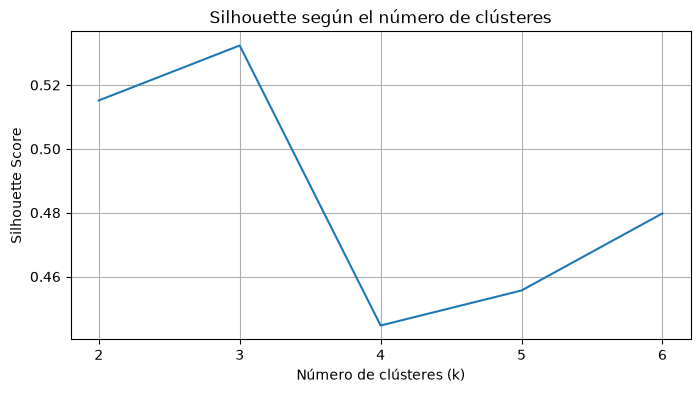

In [57]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

modelos = {}
resultados = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)
    modelos[k] = modelo

    resultados.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, etiquetas),
        "inercia": modelo.inertia_,
    })

df_resultados = pd.DataFrame(resultados)
display(df_resultados.round(3))

plt.figure(figsize=(8, 4))

sns.lineplot(
    data=df_resultados,
    x="k",
    y="silhouette",
)

plt.xticks(range(2, 7))
plt.title("Silhouette según el número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


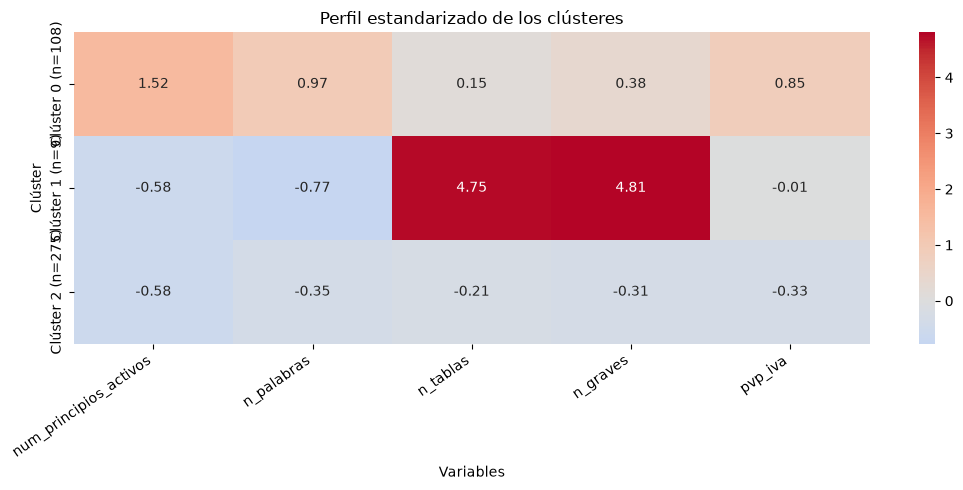

In [60]:

k_elegido = 3

modelo_final = modelos[k_elegido]
etiquetas_finales = modelo_final.labels_

# Centroides en el espacio estandarizado
centroides = pd.DataFrame(
    modelo_final.cluster_centers_,
    columns=X.columns
)

# Etiquetas con el tamaño de cada grupo
tamanos = pd.Series(etiquetas_finales).value_counts()

centroides.index = [
    f"Clúster {i} (n={tamanos[i]})"
    for i in range(k_elegido)
]

plt.figure(figsize=(11, 5))

sns.heatmap(
    centroides,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Perfil estandarizado de los clústeres")
plt.xlabel("Variables")
plt.ylabel("Clúster")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


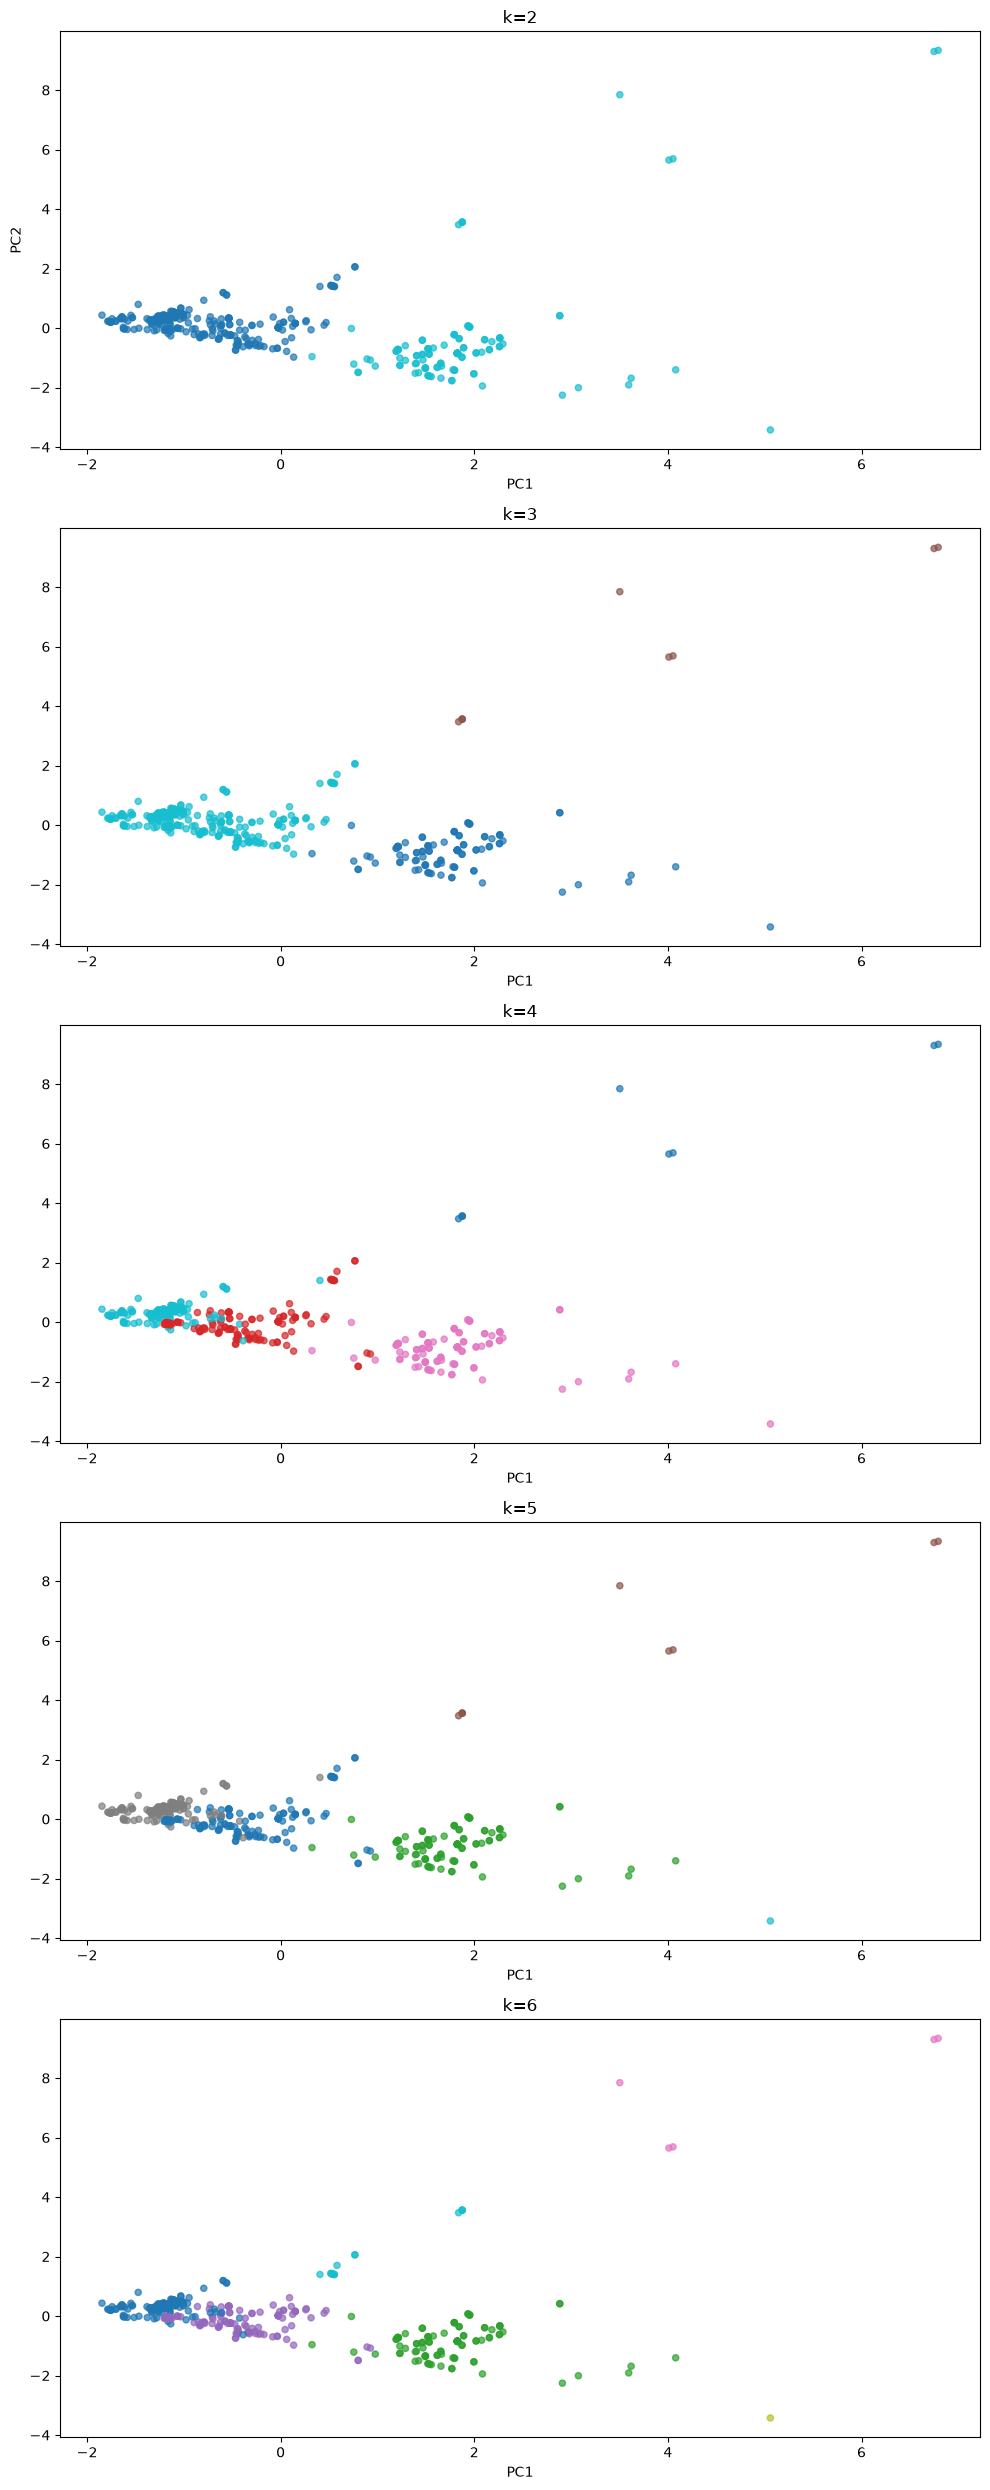

In [61]:
fig, axes = plt.subplots(5, 1, figsize=(10, 25))
for k, ax in zip(range(2, 7), axes):
    ax.scatter(*Z.T, c=modelos[k].labels_, cmap="tab10", s=20, alpha=.7)
    ax.set(title=f"k={k}", xlabel="PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()